# 7. Hafta | Proje: Öğrenci Başarısı Sınıflandırması (Makine Öğrenmesi)

**Araştırma sorusu:** Öğrencinin demografik, sosyal ve akademik özellikleri, matematik dersini geçip geçmeyeceğini (G3 ≥ 10) ne ölçüde tahmin eder?

**Veri:** UCI Student Performance, DOI: 10.24432/C5TG7T, CC BY 4.0. Gerçek, açık erişimli veridir; anket yapılmamıştır.

Bu defterde iki deney yapılır:
1. **Deney A (G1 ve G2 dahil):** önceki dönem notlarıyla tahmin.
2. **Deney B (G1 ve G2 hariç):** yalnızca sosyal/demografik özelliklerle tahmin. G1/G2, G3 ile çok yüksek ilişkilidir; bu nedenle ikinci deney daha zor ve daha "erken uyarı" niteliğinde bir senaryodur.

## 1. Veri okuma

In [1]:
import io, zipfile, urllib.request
from pathlib import Path
import pandas as pd

# Veri: UCI Student Performance (Cortez, 2014) - DOI: 10.24432/C5TG7T - Lisans: CC BY 4.0
CSV = Path("../data/student-mat.csv")
if not CSV.exists():
    CSV = Path("student-mat.csv")
if not CSV.exists():  # Colab'da dosya yoksa resmi UCI adresinden indir
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    z1 = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    z2 = zipfile.ZipFile(io.BytesIO(z1.read("student.zip")))
    CSV.write_bytes(z2.read("student-mat.csv"))
veri = pd.read_csv(CSV, sep=";")
print("Boyut (satır, sütun):", veri.shape)
veri.head()

Boyut (satır, sütun): (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Hedef değişken ve ön işleme
`basari` = 1 eğer G3 ≥ 10, aksi halde 0. Kategorik değişkenler one-hot kodlama ile sayısallaştırılır.

In [2]:
from pathlib import Path
OUT = Path("../outputs") if Path("../outputs").exists() else Path("outputs")
OUT.mkdir(exist_ok=True)
veri["basari"] = (veri["G3"] >= 10).astype(int)
print("Sınıf dağılımı:\n", veri["basari"].value_counts().rename({1: "Başarılı", 0: "Başarısız"}))
print("Eksik değer:", int(veri.isna().sum().sum()))
hedef = veri["basari"]
tam = pd.get_dummies(veri.drop(columns=["G3", "basari"]), drop_first=True)
sosyal = tam.drop(columns=["G1", "G2"])
print("Deney A özellik sayısı:", tam.shape[1], "| Deney B özellik sayısı:", sosyal.shape[1])

Sınıf dağılımı:
 basari
Başarılı     265
Başarısız    130
Name: count, dtype: int64
Eksik değer: 0
Deney A özellik sayısı: 41 | Deney B özellik sayısı: 39


## 3. Eğitim/test ayrımı (%80 / %20, `stratify`, `random_state=42`)

In [3]:
from sklearn.model_selection import train_test_split
XA_e, XA_t, y_e, y_t = train_test_split(tam, hedef, test_size=0.20, random_state=42, stratify=hedef)
XB_e, XB_t, _, _ = train_test_split(sosyal, hedef, test_size=0.20, random_state=42, stratify=hedef)
print("Eğitim:", len(y_e), "Test:", len(y_t))

Eğitim: 316 Test: 79


## 4. Modeller: Karar Ağacı, Rastgele Orman ve karşılaştırma için çoğunluk sınıfı (baseline)

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
sonuc = []
modeller = {}
for deney, (Xe, Xt) in {"A (G1,G2 dahil)": (XA_e, XA_t), "B (G1,G2 hariç)": (XB_e, XB_t)}.items():
    for ad, m in {"Çoğunluk (baseline)": DummyClassifier(strategy="most_frequent"),
                  "Karar Ağacı (max_depth=4)": DecisionTreeClassifier(max_depth=4, random_state=42),
                  "Rastgele Orman (200 ağaç)": RandomForestClassifier(n_estimators=200, random_state=42)}.items():
        m.fit(Xe, y_e); t = m.predict(Xt)
        sonuc.append({"Deney": deney, "Model": ad, "Doğruluk": round(accuracy_score(y_t, t), 4),
                      "F1 (başarılı sınıf)": round(f1_score(y_t, t), 4)})
        modeller[(deney, ad)] = (m, t)
tablo = pd.DataFrame(sonuc)
tablo

,Deney,Model,Doğruluk,F1 (başarılı sınıf)
0,"A (G1,G2 dahil)",Çoğunluk (baseline),0.6709,0.8030
1,"A (G1,G2 dahil)",Karar Ağacı (max_depth=4),0.8734,0.8980
2,"A (G1,G2 dahil)",Rastgele Orman (200 ağaç),0.8734,0.9000
3,"B (G1,G2 hariç)",Çoğunluk (baseline),0.6709,0.8030
4,"B (G1,G2 hariç)",Karar Ağacı (max_depth=4),0.6456,0.7455
5,"B (G1,G2 hariç)",Rastgele Orman (200 ağaç),0.6582,0.7769


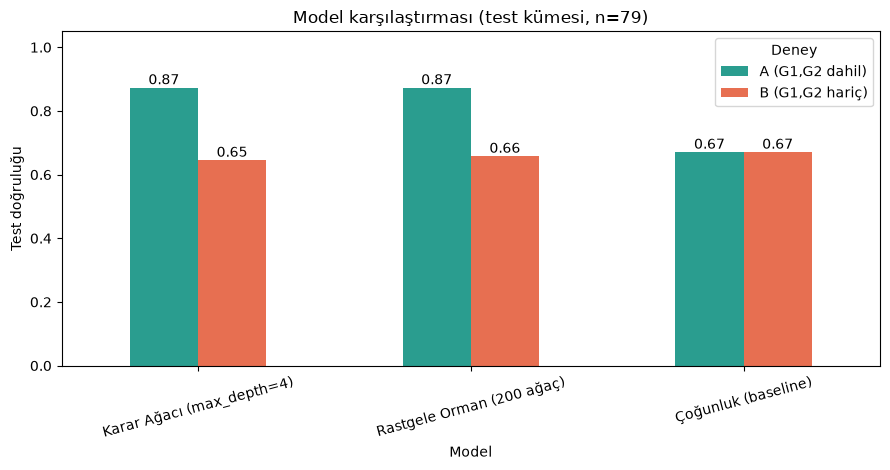

In [5]:
tablo.to_csv(OUT / "hafta7_model_karsilastirma.csv", index=False)
import matplotlib.pyplot as plt
piv = tablo.pivot(index="Model", columns="Deney", values="Doğruluk")
ax = piv.plot(kind="bar", figsize=(9, 4.8), rot=15, color=["#2a9d8f", "#e76f51"])
ax.set_ylabel("Test doğruluğu"); ax.set_ylim(0, 1.05)
ax.set_title("Model karşılaştırması (test kümesi, n=79)")
for c in ax.containers: ax.bar_label(c, fmt="%.2f")
plt.tight_layout(); plt.savefig(OUT / "hafta7_model_karsilastirma.png", dpi=160); plt.show()

## 5. Karışıklık matrisi (Karar Ağacı, Deney A ve B)

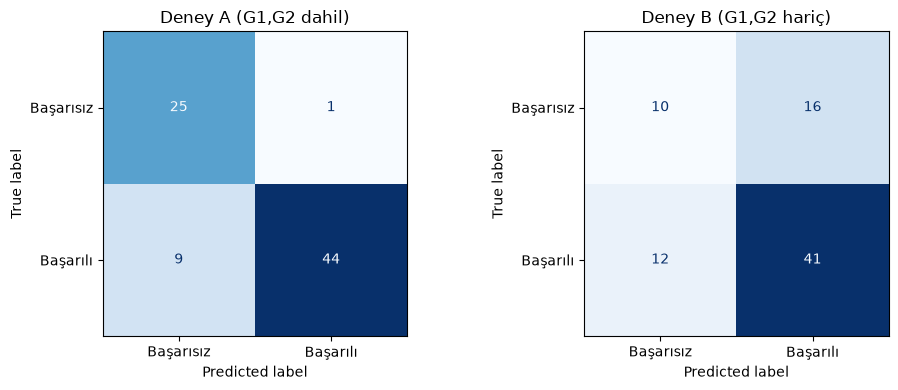

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, d in zip(axes, ["A (G1,G2 dahil)", "B (G1,G2 hariç)"]):
    t = modeller[(d, "Karar Ağacı (max_depth=4)")][1]
    ConfusionMatrixDisplay(confusion_matrix(y_t, t, labels=[0, 1]), display_labels=["Başarısız", "Başarılı"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title("Deney " + d)
plt.tight_layout(); plt.savefig(OUT / "hafta7_karisiklik_matrisi.png", dpi=160); plt.show()

## 6. Karar ağacı ve özellik önemleri

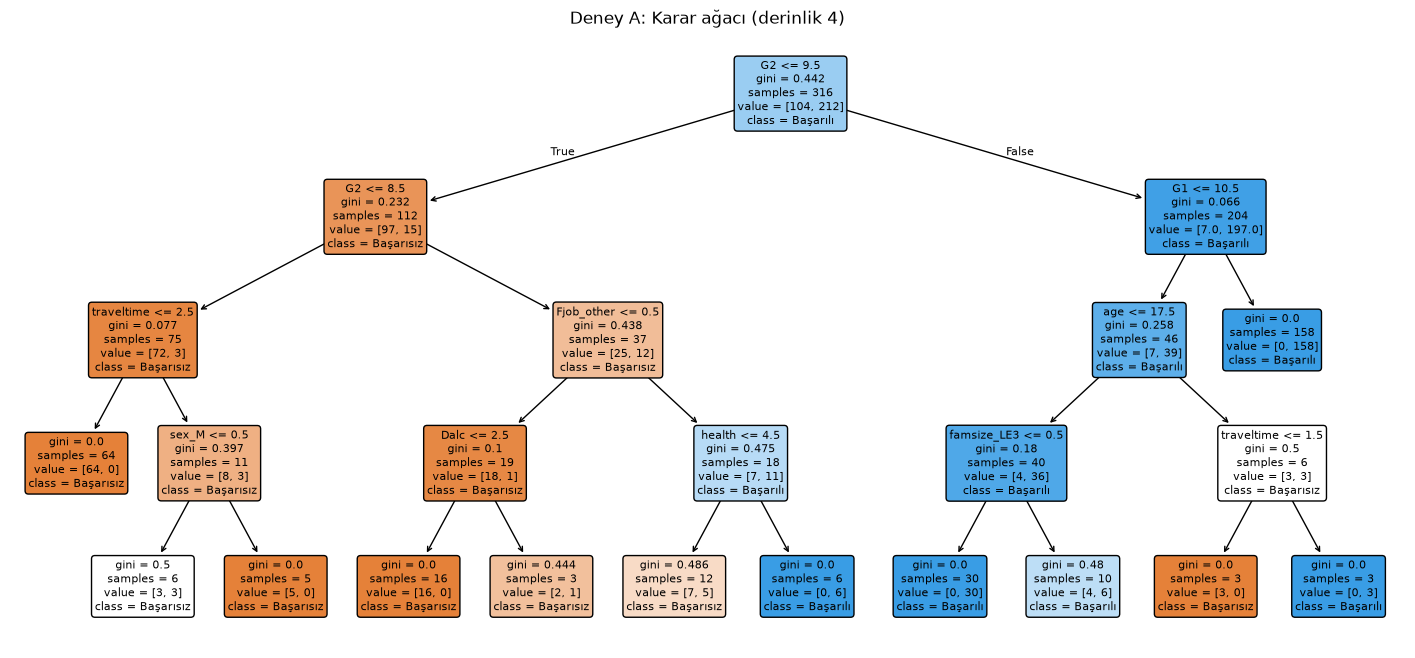

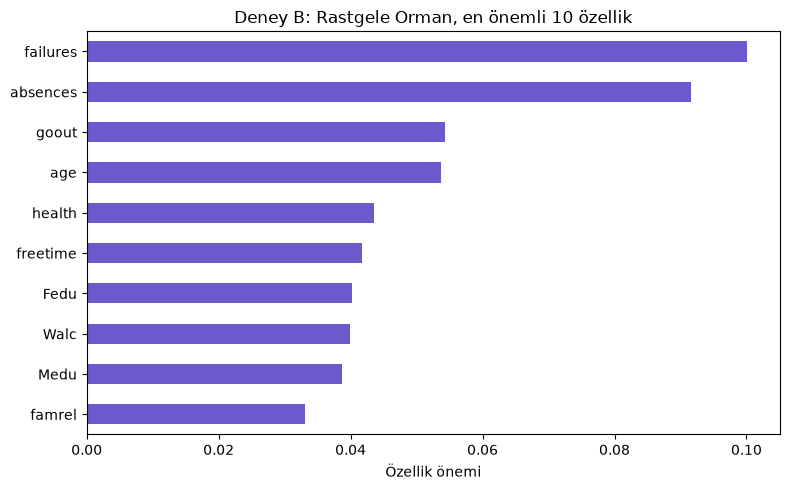

failures    0.1001
absences    0.0916
goout       0.0542
age         0.0537
health      0.0435
freetime    0.0418
Fedu        0.0402
Walc        0.0399
Medu        0.0387
famrel      0.0331
dtype: float64

In [7]:
from sklearn.tree import plot_tree
dt = modeller[("A (G1,G2 dahil)", "Karar Ağacı (max_depth=4)")][0]
plt.figure(figsize=(18, 8))
plot_tree(dt, feature_names=list(tam.columns), class_names=["Başarısız", "Başarılı"], filled=True, rounded=True, fontsize=8)
plt.title("Deney A: Karar ağacı (derinlik 4)")
plt.savefig(OUT / "hafta7_karar_agaci.png", dpi=140, bbox_inches="tight"); plt.show()

rf = modeller[("B (G1,G2 hariç)", "Rastgele Orman (200 ağaç)")][0]
onem = pd.Series(rf.feature_importances_, index=sosyal.columns).sort_values(ascending=False).head(10)
ax = onem[::-1].plot(kind="barh", figsize=(8, 5), color="slateblue")
ax.set_xlabel("Özellik önemi"); ax.set_title("Deney B: Rastgele Orman, en önemli 10 özellik")
plt.tight_layout(); plt.savefig(OUT / "hafta7_ozellik_onemi.png", dpi=160); plt.show()
onem.round(4)

In [8]:
import json
rapor = {"veri_kaynagi": "UCI Student Performance (student-mat.csv), DOI 10.24432/C5TG7T, CC BY 4.0",
         "egitim_sayisi": int(len(y_e)), "test_sayisi": int(len(y_t)), "random_state": 42,
         "hedef": "G3 >= 10 -> basarili", "sonuclar": sonuc}
with open(OUT / "hafta7_sonuc.json", "w", encoding="utf-8") as f:
    json.dump(rapor, f, ensure_ascii=False, indent=2)
print("hafta7_sonuc.json kaydedildi")

hafta7_sonuc.json kaydedildi


## 7. Sonuç ve sınırlılıklar
- **Deney A (G1, G2 dahil):** Karar Ağacı ve Rastgele Orman test doğruluğu 0,873; çoğunluk sınıfı (baseline) 0,671. Önceki dönem notları final başarısını güçlü biçimde tahmin eder; bu beklenen bir sonuçtur çünkü G1/G2 ile G3 yüksek ilişkilidir (r ≈ 0,80–0,90).
- **Deney B (G1, G2 hariç):** Karar Ağacı 0,646, Rastgele Orman 0,658; ikisi de çoğunluk sınıfı tahmininin (0,671) altındadır. Yani bu veri ve bu basit modellerle yalnızca sosyal/demografik değişkenler başarıyı güvenilir biçimde tahmin etmemektedir.
- **Sınırlılık:** Veri küçüktür (395 kayıt, test kümesi 79); sonuçlar rastgele bölmeye duyarlıdır, çapraz doğrulama ve hiperparametre araması yapılmamıştır. Çalışma nedensellik iddia etmez ve iki Portekiz okulunun verisine dayanır.